# Computation of Effective area

## Summary
- Load selected gamma rays and all gamma rays from MC
- Bins : 20 in Energy from 1 to 100 GeV, 10 in theta from 0 to 60° (Duan)
- Raffiner les bins par endroit? 

In [1]:
import ROOT, glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

cling::DynamicLibraryManager::loadLibrary(): libOpenGL.so.0: cannot open shared object file: No such file or directory
Error in <AutoloadLibraryMU>: Failed to load library /cvmfs/sft.cern.ch/lcg/releases/ROOT/6.28.04-740f6/x86_64-el9-gcc11-opt/lib/libEve.socling JIT session error: Failed to materialize symbols: { (main, { _ZeqRK7TStringRKNSt7__cxx1112basic_stringIcSt11char_traitsIcESaIcEEE }) }


Welcome to JupyROOT 6.28/04


## Create bins

In [2]:
# Emin = 1
# Emax_HET = 1e4
# n_E_bins_HET = 40 # 40

cos_theta_min = 0
cos_theta_max = 1
n_theta_bins = 20

energy_centers_GIEM = np.array([1.16121705e+00, 1.50918340e+00, 1.96142017e+00, 2.54917267e+00,
 3.31304908e+00, 4.30582611e+00, 7.27300221e+00, 1.22848810e+01,
 2.07504819e+01, 3.50497899e+01, 5.92028552e+01, 9.99999737e+01,
 1.68910683e+02, 2.85308264e+02, 4.81916266e+02, 8.14008272e+02])
ratios = energy_centers_GIEM[1:] / energy_centers_GIEM[:-1]
coarse_ratio = ratios[-1]

# Add 4 more bins following the coarse spacing
extended_centers = list(energy_centers_GIEM)
last_center = energy_centers_GIEM[-1]

for i in range(4):
    next_center = last_center * coarse_ratio
    extended_centers.append(next_center)
    last_center = next_center

extended_centers = np.array(extended_centers)
def calculate_bin_edges(centers):
    """Calculate bin edges from bin centers assuming log spacing"""
    edges = []
    
    # First edge: extrapolate backwards
    if len(centers) > 1:
        ratio_0_1 = centers[1] / centers[0]
        first_edge = centers[0] / np.sqrt(ratio_0_1)
    else:
        first_edge = centers[0] / 2  # fallback
    edges.append(first_edge)
    
    # Middle edges: geometric mean of adjacent centers
    for i in range(len(centers) - 1):
        edge = np.sqrt(centers[i] * centers[i + 1])
        edges.append(edge)
    
    # Last edge: extrapolate forwards
    if len(centers) > 1:
        ratio_last = centers[-1] / centers[-2]
        last_edge = centers[-1] * np.sqrt(ratio_last)
    else:
        last_edge = centers[-1] * 2  # fallback
    edges.append(last_edge)
    
    return np.array(edges)

# Calculate edges for the extended centers
E_bins_edge_HET = calculate_bin_edges(extended_centers)

# E_bins_edge_HET = np.logspace(np.log10(Emin), np.log10(Emax_HET), n_E_bins_HET + 1)
E_bins_center_HET = np.sqrt(E_bins_edge_HET[:-1] * E_bins_edge_HET[1:])

n_E_bins_HET = len(E_bins_center_HET)

print(f"Extended centers : {extended_centers}")
print(f"Computed bin centers : {E_bins_center_HET}")

theta_bins_edge = np.linspace(cos_theta_min, cos_theta_max, n_theta_bins + 1)
theta_bins_center = (theta_bins_edge[:-1] + theta_bins_edge[1:])/2

Extended centers : [1.16121705e+00 1.50918340e+00 1.96142017e+00 2.54917267e+00
 3.31304908e+00 4.30582611e+00 7.27300221e+00 1.22848810e+01
 2.07504819e+01 3.50497899e+01 5.92028552e+01 9.99999737e+01
 1.68910683e+02 2.85308264e+02 4.81916266e+02 8.14008272e+02
 1.37494730e+03 2.32243348e+03 3.92283930e+03 6.62609641e+03]
Computed bin centers : [1.16121705e+00 1.50918340e+00 1.96142017e+00 2.54917267e+00
 3.31304908e+00 4.59741428e+00 7.27300222e+00 1.22848810e+01
 2.07504819e+01 3.50497899e+01 5.92028552e+01 9.99999736e+01
 1.68910683e+02 2.85308264e+02 4.81916266e+02 8.14008272e+02
 1.37494730e+03 2.32243348e+03 3.92283930e+03 6.62609641e+03]


In [3]:
def browse_files(filenames):
    """
    Browse through the list of filenames and return a sorted list of files.
    """
    if isinstance(filenames, str):
        files = sorted(glob.glob(filenames))
    elif isinstance(filenames, list):
        files = []
        for filename in filenames:
            files += sorted(glob.glob(filename))
    else:
        raise ValueError("Input should be a string or a list of strings.")
    
    return files


## Load MC data

In [4]:
dirDir= "/home/users/l/lebrun/"
dataDir = "/dpnc/beegfs/dampe/tryf/MC_Skimmed/MC_gamma/"
figPath_ = dirDir + "figures/"
resultPath = dirDir + "results/"
dataPath1 = dirDir + "data/"
dataPath2 = "/dpnc/beegfs/dampe/tryf/ForKimberly/"
# filename1 = dataDir + "DmlNtup_gamma_part*_TQ_FullSel.root"
# filename2 = dataDir + "DmlNtup_gamma_100GeV_1TeV_part*_TQ_FullSel.root"
# filename3 = dataDir + "DmlNtup_gamma_1TeV_10TeV_part*_MPhotonSelProj_TQ_FullSel.root"

# filenames_LET = [filename1, filename2]
# filenames_HET = [filename1, filename2, filename3]

# Find all matching ROOT files : from 1 GeV to 100 GeV
# files = list()
# for filename in filenames_HET:
#     files += sorted(glob.glob(filename))
exponent = 0

figPath = figPath_+f"effArea/exp{exponent:.1f}/"
# file = dataPath + f"MC_exp{exponent:.1f}.root"

dataPath_scaled = dataPath2 + "tt_scaled" + "_cos_theta_bins/"
dataPath_scaled += f"exp{exponent:.1f}/"

files_scaled = browse_files(dataPath_scaled + "*.root")

dataPath_filtered = dataPath2 + "tt_filtered" + "_cos_theta_bins/"
dataPath_filtered += f"exp{exponent:.1f}/"
print(f"dataPath_filtered: {dataPath_filtered}")

files_filtered = browse_files(dataPath_filtered + "*.root")

# Pass the list of files to RDataFrame
# DmlNtup
print(f"Loading files: {files_scaled}")
rdf = ROOT.RDataFrame("MC", files_scaled)

print(f"Loading files: {files_filtered}")
rdf_filtered = ROOT.RDataFrame("MC", files_filtered)
rdf_filtered = rdf_filtered.Filter("tt_isHET == 1")

# # Apply cut on FoV
# rdf = rdf.Filter("theta_True < 60")


dataPath_filtered: /dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/
Loading files: ['/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_0.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_1.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_10.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_11.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_12.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_13.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_14.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_15.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_16.root', '/dpn

In [5]:
# Extract only desired columns

df = rdf.AsNumpy(["E_true", "weight", "tt_theta", "theta_BestSTK", 'tt_bgoTotalEcorr_GeV'])
df = pd.DataFrame(df)
print("Number of entries in original : ", len(df))

Number of entries in original :  181572808


## Necessary transformations

In [6]:
# Print min max of E_true
print(f"Minimum E_true: {df['E_true'].min()} GeV")
print(f"Maximum E_true: {df['E_true'].max()} GeV")

df = df.loc[(df['tt_theta'] < np.pi) & (df['tt_theta'] > -np.pi)]
df = df.rename(columns={'tt_theta' : 'theta_True'})

df['theta_True_deg']= np.rad2deg(df['theta_True'])
print(f"Minimum theta_True: {df['theta_True_deg'].min()} degrees")
print(f"Maximum theta_True: {df['theta_True_deg'].max()} degrees")

df['cosTheta'] = np.cos(df['theta_True'])


Minimum E_true: -7.714181677271262e-42 GeV
Maximum E_true: 9999.96505258949 GeV
Minimum theta_True: 0.02498552615822781 degrees
Maximum theta_True: 89.99999169247724 degrees


## TODO : load filtered data

In [7]:
# Load filtered data here
#dfHET = pd.read_csv(dataPath + f"MC_het_exp{exponent:.1f}_filtered_energy.csv")
dfHET = rdf_filtered.AsNumpy(["weight", "tt_theta", "tt_isHET", "tt_ekin", "theta_BestSTK", "tt_bgoTotalEcorr_GeV"])
dfHET = pd.DataFrame(dfHET)

dfHET = dfHET.rename(columns={'tt_theta' : 'theta_True'})

# Print number of events
# Print number of event in df
print(f"Number of events in original data: {len(df)}")
print(f"Number of events in filtered data: {len(dfHET)}")

# Filter the DataFrame to keep only HET events
dfHET = dfHET[dfHET['tt_isHET'] == 1]
# Print number of HET events
print(f"Number of HET events: {len(dfHET)}")
# Add energy column in GeV
# TODO : assess and change / remove
#dfHET['E_true'] = dfHET['tt_ekin'] * 1e-3 # Convert tt_ekin from MeV to GeV
dfHET['E_true'] = dfHET["tt_bgoTotalEcorr_GeV"]
# Print min max of E_true
print(f"Minimum E_true: {dfHET['E_true'].min()} GeV")
print(f"Maximum E_true: {dfHET['E_true'].max()} GeV")

dfHET = dfHET[dfHET['E_true'] <= 1e4]
print(f"Number of HET events with E_true <= 10 TeV: {len(dfHET)}")

dfHET['theta_True_deg']= np.rad2deg(dfHET['theta_True'])

dfHET['cosTheta'] = np.cos(dfHET['theta_True'])

print(f"Minimum theta_True: {dfHET['theta_True_deg'].min()} degrees")
print(f"Maximum theta_True: {dfHET['theta_True_deg'].max()} degrees")

# dfHET = dfHET[dfHET['theta_True_deg'] < 60]
# print(f"Number of HET events with theta_True < 60: {len(dfHET)}")

Number of events in original data: 181572671
Number of events in filtered data: 1482452
Number of HET events: 1482452
Minimum E_true: 0.21299671331695502 GeV
Maximum E_true: 10088.44012928127 GeV
Number of HET events with E_true <= 10 TeV: 1482438
Minimum theta_True: 0.08214076561272729 degrees
Maximum theta_True: 89.97767053951249 degrees


### Check Spectra

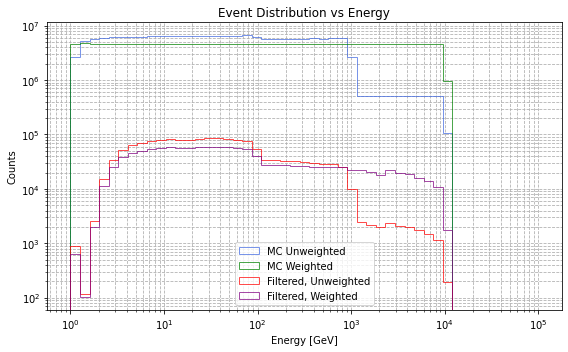

In [8]:
nbins=50

plt.figure(figsize=(8, 5))
plt.hist(df['E_true'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='royalblue', histtype='step', label='MC Unweighted', alpha=0.7)
plt.hist(df['E_true'], weights=df['weight'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='green', histtype='step', label='MC Weighted', alpha=0.7)
plt.hist(dfHET['E_true'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='red', histtype='step', label='Filtered, Unweighted', alpha=0.7)
plt.hist(dfHET['E_true'], weights=dfHET['weight'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='purple', histtype='step', label='Filtered, Weighted', alpha=0.7)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Energy [GeV]")
plt.ylabel("Counts")
plt.title("Event Distribution vs Energy")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.savefig(figPath + f"energy_spectrum_comparison_exp{exponent:.1f}.png", dpi=400)
plt.show()

### Check angles

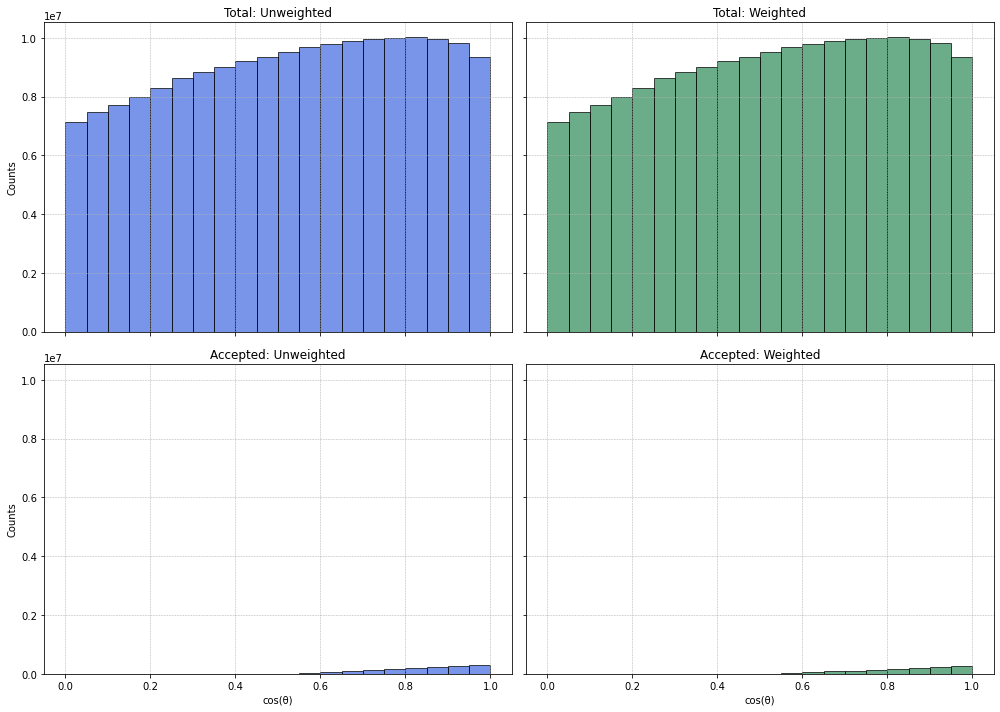

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

# 1. total unweighted
axs[0, 0].hist(df['cosTheta'], bins=theta_bins_edge, color='royalblue', alpha=0.7, edgecolor='black')
axs[0, 0].set_title('Total: Unweighted')
axs[0, 0].set_ylabel('Counts')
axs[0, 0].grid(True, which="both", ls="--", lw=0.5)

# 2. total weighted
axs[0, 1].hist(df['cosTheta'], bins=theta_bins_edge, weights=df['weight'], color='seagreen', alpha=0.7, edgecolor='black')
axs[0, 1].set_title('Total: Weighted')
axs[0, 1].grid(True, which="both", ls="--", lw=0.5)

# 3. Accepted unweighted
axs[1, 0].hist(dfHET['cosTheta'], bins=theta_bins_edge, color='royalblue', alpha=0.7, edgecolor='black')
axs[1, 0].set_title('Accepted: Unweighted')
axs[1, 0].set_xlabel('cos(θ)')
axs[1, 0].set_ylabel('Counts')
axs[1, 0].grid(True, which="both", ls="--", lw=0.5)

# 4. Accepted weighted
axs[1, 1].hist(dfHET['cosTheta'], bins=theta_bins_edge, weights=dfHET['weight'], color='seagreen', alpha=0.7, edgecolor='black')
axs[1, 1].set_title('Accepted: Weighted')
axs[1, 1].set_xlabel('cos(θ)')
axs[1, 1].grid(True, which="both", ls="--", lw=0.5)

plt.tight_layout()
plt.show()

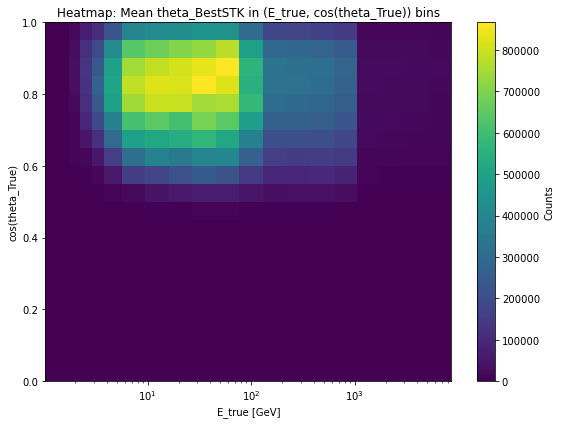

In [10]:
plt.figure(figsize=(8, 6))
plt.hist2d(
    dfHET['tt_ekin'] * 1e-3,                # X axis: Energy in GeV
    dfHET['cosTheta'],                    # Y axis: cos(theta_True) (already computed in dfHET)
    bins=[E_bins_edge_HET, theta_bins_edge],
    weights=dfHET['theta_BestSTK'],       # Heatmap value: theta_BestSTK
    cmap='viridis'
)
plt.xscale('log')
plt.xlabel('E_true [GeV]')
plt.ylabel('cos(theta_True)')
plt.title('Heatmap: Mean theta_BestSTK in (E_true, cos(theta_True)) bins')
plt.colorbar(label='Counts')
plt.tight_layout()
plt.show()

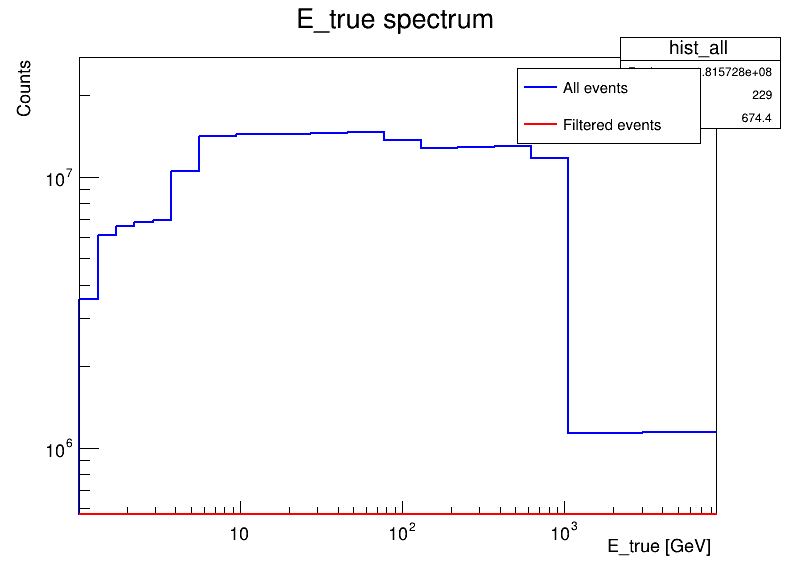

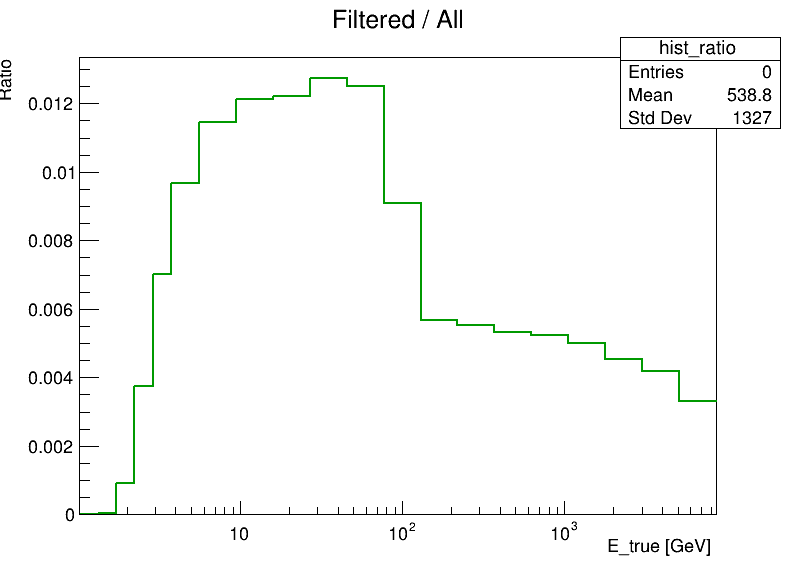

In [11]:

# Create histograms
hist_all = rdf.Histo1D(
    ("hist_all", "E_true spectrum;E_true [GeV];Counts", n_E_bins_HET, E_bins_edge_HET),
    "E_true"
)

hist_filtered = rdf_filtered.Histo1D(
    ("hist_filtered", "Filtered E_true spectrum;E_true [GeV];Counts", n_E_bins_HET, E_bins_edge_HET),
    "E_true"
)

# Draw the two spectra on the same canvas
c1 = ROOT.TCanvas("c1", "Spectra", 800, 600)
c1.SetLogx()
c1.SetLogy()

hist_all.SetLineColor(ROOT.kBlue)
hist_all.SetLineWidth(2)
hist_filtered.SetLineColor(ROOT.kRed)
hist_filtered.SetLineWidth(2)

hist_all.Draw("HIST")
hist_filtered.Draw("HIST SAME")

# max_y= max((hist_all.GetMaximum(), hist_filtered.GetMaximum())) * 1.2
# min_y = min((hist_all.GetMinimum(1), hist_filtered.GetMinimum(1)))
# min_y = max(min_y, 1e-3)

# hist_all.SetMaximum(max_y)
# hist_all.SetMinimum(min_y)

# hist_filtered.SetMaximum(max_y)
# hist_filtered.SetMinimum(min_y)

legend = ROOT.TLegend(0.65, 0.75, 0.88, 0.88)
legend.AddEntry(hist_all.GetPtr(), "All events", "l")
legend.AddEntry(hist_filtered.GetPtr(), "Filtered events", "l")
legend.Draw()

c1.Draw()

# Create ratio histogram
hist_ratio = hist_filtered.Clone("hist_ratio")
hist_ratio.SetTitle("Filtered / All;E_true [GeV];Ratio")
hist_ratio.Divide(hist_all.GetPtr())  # GetPtr() ensures the C++ object is used

# Draw the ratio
c2 = ROOT.TCanvas("c2", "Ratio", 800, 600)
c2.SetLogx()
hist_ratio.SetLineColor(ROOT.kGreen + 2)
hist_ratio.SetLineWidth(2)
hist_ratio.Draw("HIST")
c2.Draw()

### ROOT approach, with weights

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c2


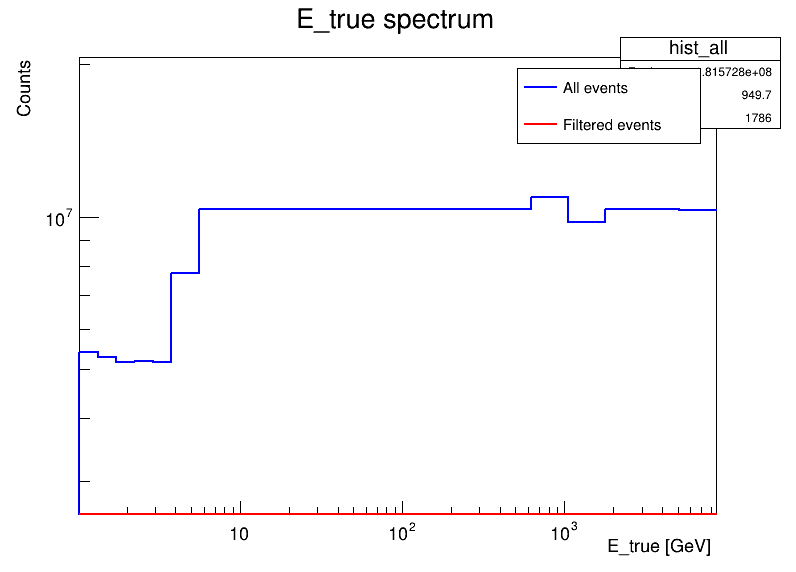

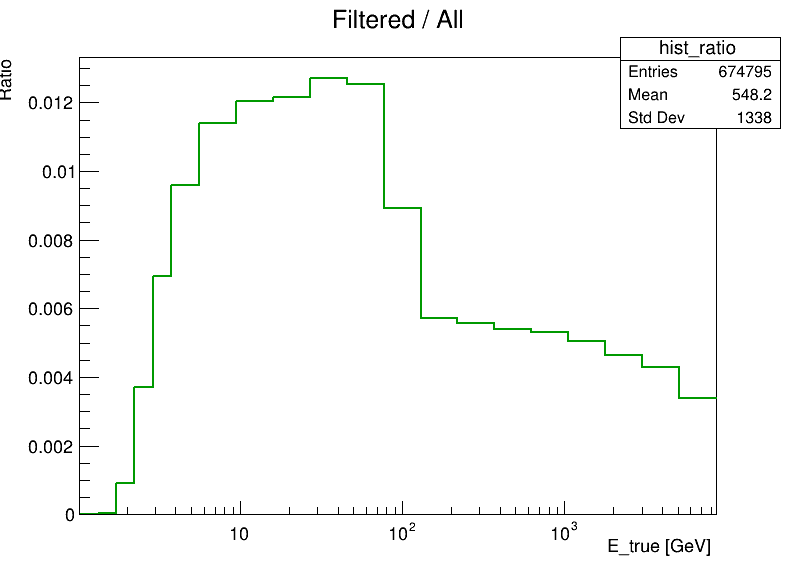

In [12]:

# Create histograms
hist_all = rdf.Histo1D(
    ("hist_all", "E_true spectrum;E_true [GeV];Counts", n_E_bins_HET, E_bins_edge_HET),
    "E_true", "weight"
)

hist_filtered = rdf_filtered.Histo1D(
    ("hist_filtered", "Filtered E_true spectrum;E_true [GeV];Counts", n_E_bins_HET, E_bins_edge_HET),
    "E_true", "weight"
)

# Draw the two spectra on the same canvas
c3 = ROOT.TCanvas("c1", "Spectra", 800, 600)
c3.SetLogx()
c3.SetLogy()

hist_all.SetLineColor(ROOT.kBlue)
hist_all.SetLineWidth(2)
hist_filtered.SetLineColor(ROOT.kRed)
hist_filtered.SetLineWidth(2)

hist_all.Draw("HIST")
hist_filtered.Draw("HIST SAME")

# max_y= max((hist_all.GetMaximum(), hist_filtered.GetMaximum())) * 1.2
# min_y = min((hist_all.GetMinimum(1), hist_filtered.GetMinimum(1)))
# min_y = max(min_y, 1e-3)

# hist_all.SetMaximum(max_y)
# hist_all.SetMinimum(min_y)

# hist_filtered.SetMaximum(max_y)
# hist_filtered.SetMinimum(min_y)

legend = ROOT.TLegend(0.65, 0.75, 0.88, 0.88)
legend.AddEntry(hist_all.GetPtr(), "All events", "l")
legend.AddEntry(hist_filtered.GetPtr(), "Filtered events", "l")
legend.Draw()

c3.Draw()

# Create ratio histogram
hist_ratio = hist_filtered.Clone("hist_ratio")
hist_ratio.SetTitle("Filtered / All;E_true [GeV];Ratio")
hist_ratio.Divide(hist_all.GetPtr())  # GetPtr() ensures the C++ object is used

# Draw the ratio
c4 = ROOT.TCanvas("c2", "Ratio", 800, 600)
c4.SetLogx()
hist_ratio.SetLineColor(ROOT.kGreen + 2)
hist_ratio.SetLineWidth(2)
hist_ratio.Draw("HIST")
c4.Draw()

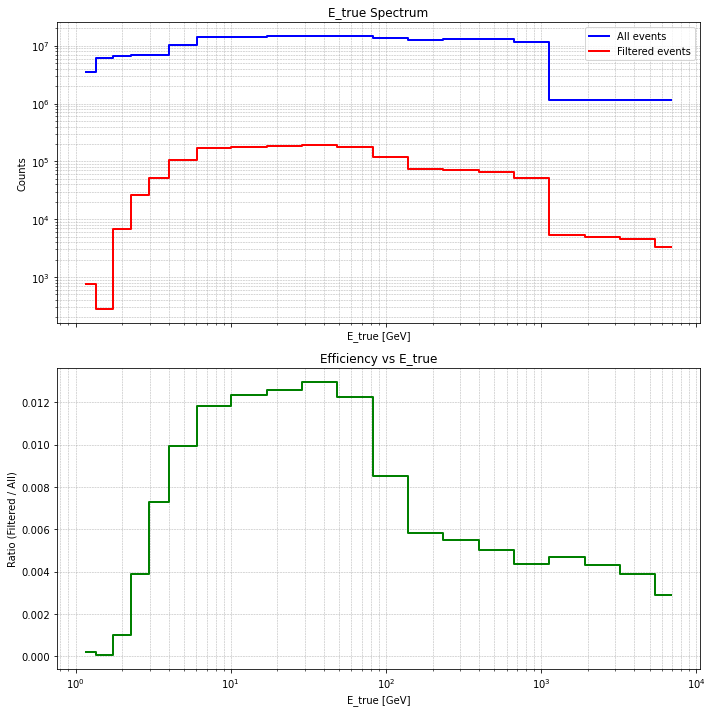

In [13]:
# Step 1: Create histograms
hist_all_counts, bin_edges = np.histogram(df["E_true"], bins=E_bins_edge_HET)
hist_filtered_counts, _ = np.histogram(dfHET["E_true"], bins=E_bins_edge_HET)

# Step 2: Plot histograms (like ROOT canvas c1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
fig, axs = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

axs[0].plot(bin_centers, hist_all_counts, drawstyle='steps-mid', label="All events", color='blue', linewidth=2)
axs[0].plot(bin_centers, hist_filtered_counts, drawstyle='steps-mid', label="Filtered events", color='red', linewidth=2)
axs[0].set_xscale("log")
axs[0].set_yscale("log")
axs[0].set_xlabel("E_true [GeV]")
axs[0].set_ylabel("Counts")
axs[0].set_title("E_true Spectrum")
axs[0].legend(loc="upper right")
axs[0].grid(True, which="both", ls="--", lw=0.5)
plt.tight_layout()

# Avoid division by zero
with np.errstate(divide='ignore', invalid='ignore'):
    ratio = np.divide(hist_filtered_counts, hist_all_counts)
    ratio[hist_all_counts == 0] = np.nan  

axs[1].plot(bin_centers, ratio, drawstyle='steps-mid', color='green', linewidth=2)
axs[1].set_xscale("log")
axs[1].set_xlabel("E_true [GeV]")
axs[1].set_ylabel("Ratio (Filtered / All)")
axs[1].set_title("Efficiency vs E_true")
axs[1].grid(True, which="both", ls="--", lw=0.5)
plt.tight_layout()
plt.show()


### Filter over FoV delimited by theta_bins

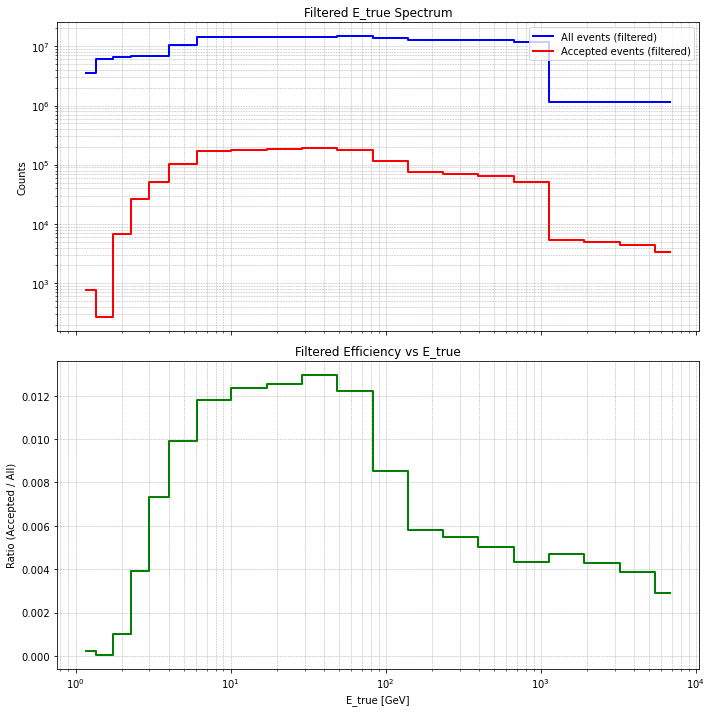

In [14]:
# Apply the same cosTheta filtering as the 2D histogram
theta_min, theta_max = theta_bins_edge[0], theta_bins_edge[-1]

# Filter data to only include events within theta range
df_filtered = df[(df['cosTheta'] >= theta_min) & (df['cosTheta'] <= theta_max)]
dfHET_filtered = dfHET[(dfHET['cosTheta'] >= theta_min) & (dfHET['cosTheta'] <= theta_max)]

# Now create 1D histograms with filtered data
hist_all_counts_filtered, bin_edges = np.histogram(df_filtered["E_true"], bins=E_bins_edge_HET)
hist_accepted_counts_filtered, _ = np.histogram(dfHET_filtered["E_true"], bins=E_bins_edge_HET)

# Calculate ratio
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
with np.errstate(divide='ignore', invalid='ignore'):
    ratio_1d_filtered = np.divide(hist_accepted_counts_filtered, hist_all_counts_filtered)
    ratio_1d_filtered[hist_all_counts_filtered == 0] = np.nan

fig, axs = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# Top subplot: filtered histograms
axs[0].plot(bin_centers, hist_all_counts_filtered, drawstyle='steps-mid', label="All events (filtered)", color='blue', linewidth=2)
axs[0].plot(bin_centers, hist_accepted_counts_filtered, drawstyle='steps-mid', label="Accepted events (filtered)", color='red', linewidth=2)
axs[0].set_xscale("log")
axs[0].set_yscale("log")
axs[0].set_ylabel("Counts")
axs[0].set_title("Filtered E_true Spectrum")
axs[0].legend(loc="upper right")
axs[0].grid(True, which="both", ls="--", lw=0.5)

# Bottom subplot: ratio
axs[1].plot(bin_centers, ratio_1d_filtered, drawstyle='steps-mid', color='green', linewidth=2)
axs[1].set_xscale("log")
axs[1].set_xlabel("E_true [GeV]")
axs[1].set_ylabel("Ratio (Accepted / All)")
axs[1].set_title("Filtered Efficiency vs E_true")
axs[1].grid(True, which="both", ls="--", lw=0.5)

plt.tight_layout()
plt.show()

### Add weights

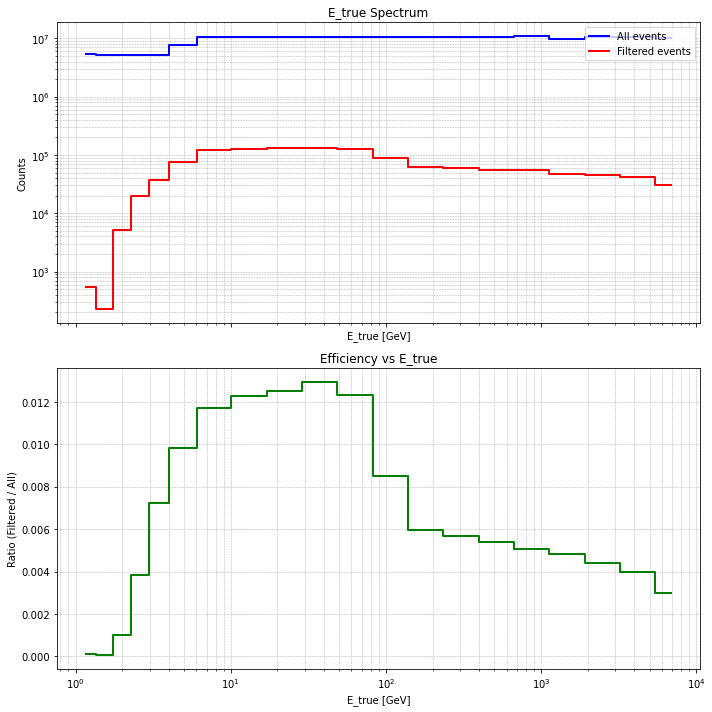

In [15]:
# Step 1: Create histograms
hist_all_counts, bin_edges = np.histogram(df["E_true"], bins=E_bins_edge_HET, weights=df["weight"])
hist_filtered_counts, _ = np.histogram(dfHET["E_true"], bins=E_bins_edge_HET, weights = dfHET["weight"])

# Step 2: Plot histograms (like ROOT canvas c1)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
fig, axs = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

axs[0].plot(bin_centers, hist_all_counts, drawstyle='steps-mid', label="All events", color='blue', linewidth=2)
axs[0].plot(bin_centers, hist_filtered_counts, drawstyle='steps-mid', label="Filtered events", color='red', linewidth=2)
axs[0].set_xscale("log")
axs[0].set_yscale("log")
axs[0].set_xlabel("E_true [GeV]")
axs[0].set_ylabel("Counts")
axs[0].set_title("E_true Spectrum")
axs[0].legend(loc="upper right")
axs[0].grid(True, which="both", ls="--", lw=0.5)
plt.tight_layout()

# Avoid division by zero
with np.errstate(divide='ignore', invalid='ignore'):
    ratio = np.divide(hist_filtered_counts, hist_all_counts)
    ratio[hist_all_counts == 0] = np.nan  

axs[1].plot(bin_centers, ratio, drawstyle='steps-mid', color='green', linewidth=2)
axs[1].set_xscale("log")
axs[1].set_xlabel("E_true [GeV]")
axs[1].set_ylabel("Ratio (Filtered / All)")
axs[1].set_title("Efficiency vs E_true")
axs[1].grid(True, which="both", ls="--", lw=0.5)
plt.tight_layout()
plt.show()


## Try with numpy 2DHistogram

In [16]:
# Create 2D histograms using numpy
# Total events (unweighted)
total_counts, E_edges, theta_edges = np.histogram2d(
    df['E_true'], 
    df['cosTheta'], 
    bins=[E_bins_edge_HET, theta_bins_edge]
)

# Accepted events (unweighted)
accepted_counts, _, _ = np.histogram2d(
    dfHET['E_true'], 
    dfHET['cosTheta'], 
    bins=[E_bins_edge_HET, theta_bins_edge]
)

# Total events (weighted)
total_weights, _, _ = np.histogram2d(
    df['E_true'], 
    df['cosTheta'], 
    bins=[E_bins_edge_HET, theta_bins_edge],
    weights=df['weight']
)

# Accepted events (weighted)
accepted_weights, _, _ = np.histogram2d(
    dfHET['E_true'], 
    dfHET['cosTheta'], 
    bins=[E_bins_edge_HET, theta_bins_edge],
    weights=dfHET['weight']
)

In [17]:
total_counts = total_counts.T
accepted_counts = accepted_counts.T
total_weights = total_weights.T
accepted_weights = accepted_weights.T

# Calculate ratios (with protection against division by zero)
unweighted_ratio = np.divide(accepted_counts, total_counts, 
                           out=np.zeros_like(accepted_counts), 
                           where=total_counts!=0)

unweighted_efficiency = accepted_counts/np.sum(total_counts)

weighted_ratio = np.divide(accepted_weights, total_weights, 
                         out=np.zeros_like(accepted_weights), 
                         where=total_weights!=0)

weighted_efficiency = accepted_weights/np.sum(total_weights)

r = 1.38*1e2 # cm
phi_norm = 2*np.pi # used to average over azimuthal angle
df_results_geom = 37.59 * 1e4 # cm^2 sr
cross_section = 6 # m^2
eff_area_geom = 6*1e4/ phi_norm # cm^2

# Optional: Print some statistics
print(f"Total events in histogram: {np.sum(total_counts)}")
print(f"Accepted events in histogram: {np.sum(accepted_counts)}")
print(f"Overall acceptance rate: {np.sum(accepted_counts)/np.sum(total_counts):.4f}")
print(f"Total weighted events: {np.sum(total_weights):.2f}")
print(f"Accepted weighted events: {np.sum(accepted_weights):.2f}")
print(f"Overall weighted acceptance rate: {np.sum(accepted_weights)/np.sum(total_weights):.4f}")

Total events in histogram: 181233025.0
Accepted events in histogram: 1479258.0
Overall acceptance rate: 0.0082
Total weighted events: 178595717.58
Accepted weighted events: 1260983.04
Overall weighted acceptance rate: 0.0071


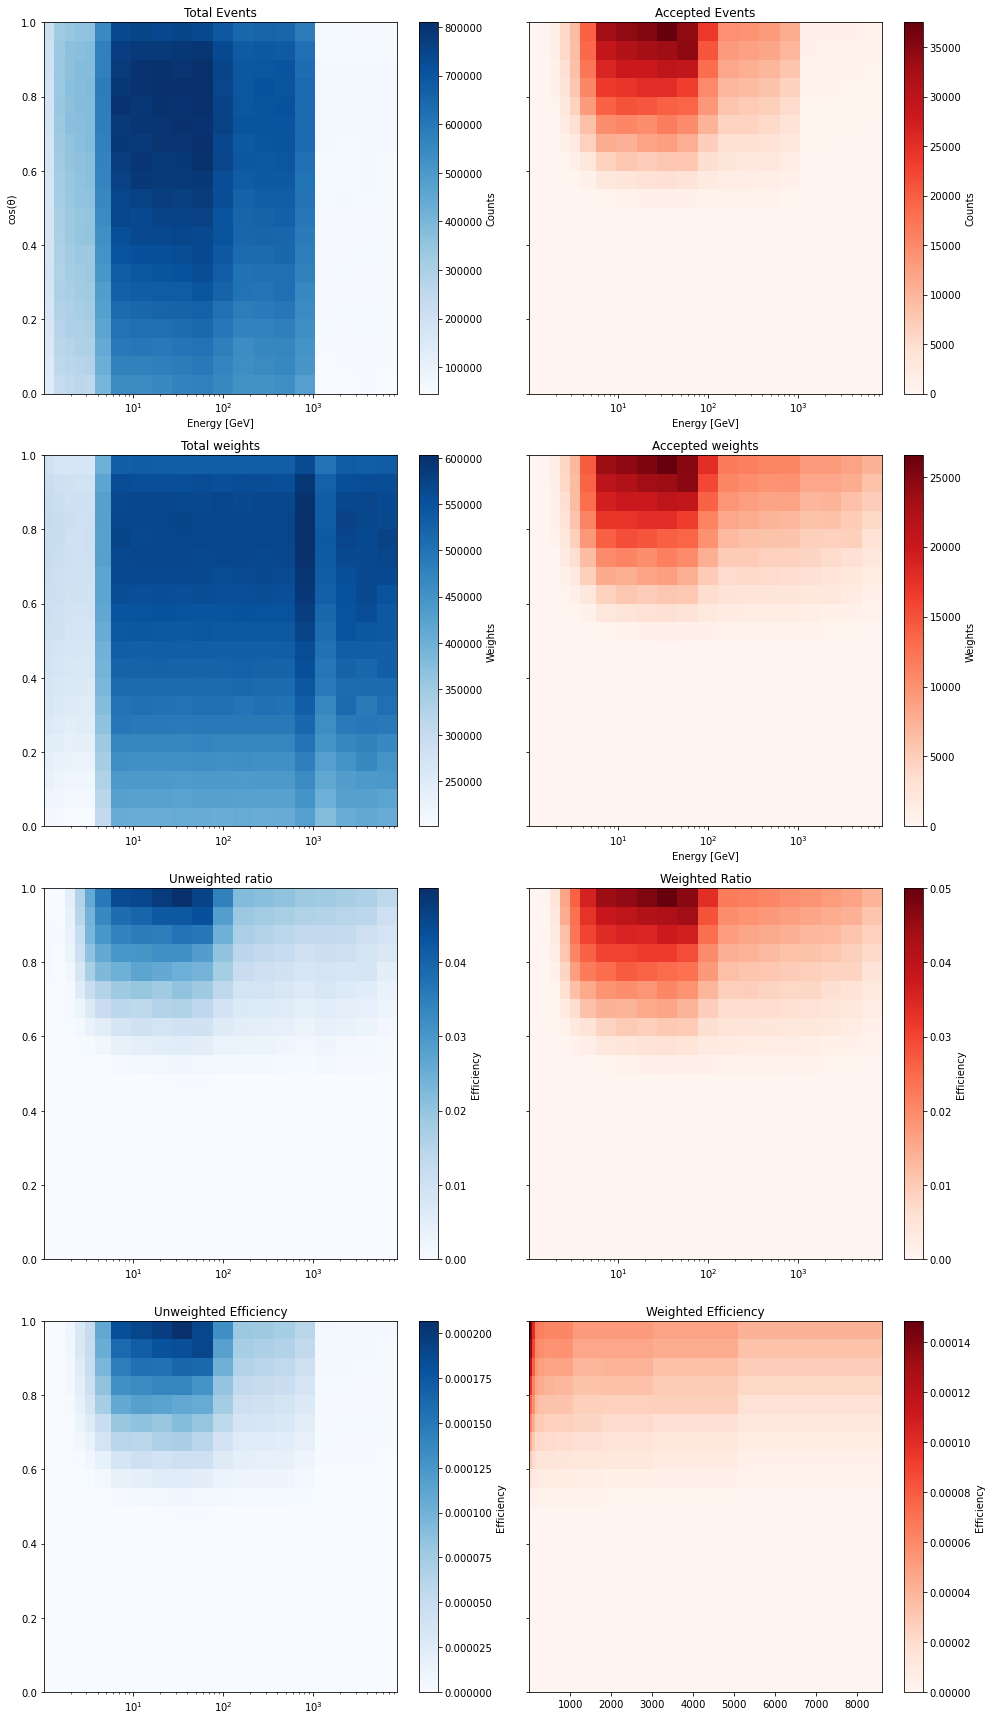

In [18]:

fig, axs = plt.subplots(4, 2, figsize=(14, 24), sharey=True)
# Plot total counts
c1 = axs[0][0].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, total_counts,
    shading='auto', cmap='Blues'
)
axs[0][0].set_xscale('log')
axs[0][0].set_xlabel("Energy [GeV]")
axs[0][0].set_ylabel("cos(θ)")
axs[0][0].set_title("Total Events")
fig.colorbar(c1, ax=axs[0][0], label='Counts')

# Plot accepted counts
c2 = axs[0][1].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, accepted_counts,
    shading='auto', cmap='Reds'
)
axs[0][1].set_xscale('log')
axs[0][1].set_xlabel("Energy [GeV]")
axs[0][1].set_title("Accepted Events")
fig.colorbar(c2, ax=axs[0][1], label='Counts')

# Plot total weights
c3 = axs[1][0].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, total_weights,
    shading='auto', cmap='Blues'
)
axs[1][0].set_xscale('log')
axs[1][0].set_title("Total weights")
fig.colorbar(c3, ax=axs[1][0], label='Weights')

# Plot accepted weights
c4 = axs[1][1].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, accepted_weights,
    shading='auto', cmap='Reds'
)
axs[1][1].set_xscale('log')
axs[1][1].set_xlabel("Energy [GeV]")
axs[1][1].set_title("Accepted weights")
fig.colorbar(c4, ax=axs[1][1], label='Weights')

# Plot unweighted ratio
c5 = axs[2][0].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, unweighted_ratio,
    shading='auto', cmap='Blues'
)
axs[2][0].set_xscale('log')
axs[2][0].set_title("Unweighted ratio")
fig.colorbar(c5, ax=axs[2][0], label='Efficiency')

# Plot weighted ratio
c6 = axs[2][1].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, weighted_ratio,
    shading='auto', cmap='Reds'
)
axs[2][1].set_xscale('log')
axs[2][1].set_title("Weighted Ratio")
fig.colorbar(c6, ax=axs[2][1], label='Efficiency')

# Plot unweighted efficiency
c7 = axs[3][0].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, unweighted_efficiency,
    shading='auto', cmap='Blues'
)
axs[3][0].set_xscale('log')
axs[3][0].set_title("Unweighted Efficiency")
fig.colorbar(c7, ax=axs[3][0], label='Efficiency')

# Plot weighted efficiency
c8 = axs[3][1].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, weighted_efficiency,
    shading='auto', cmap='Reds'
)
axs[3][1].set_title("Weighted Efficiency")
fig.colorbar(c8, ax=axs[3][1], label='Efficiency')

plt.tight_layout()
fig.savefig(figPath + "effAreaComparison.png")
plt.show()

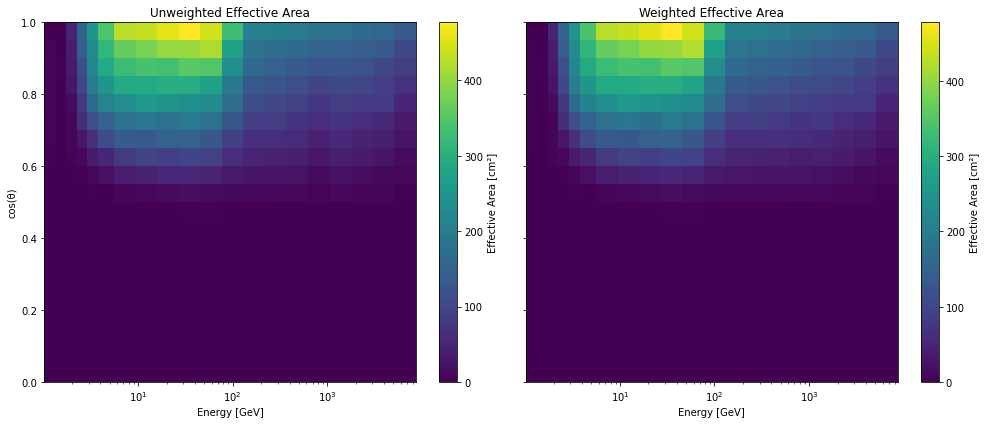

In [19]:
effArea = unweighted_ratio * eff_area_geom
effArea_w = weighted_ratio * eff_area_geom

# Prepare color scale (optional: shared scale)
vmin = np.nanmin([effArea, effArea_w])
vmax = np.nanmax([effArea, effArea_w])

fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Unweighted
c1 = axs[0].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, effArea,
    shading='auto', cmap='viridis'#, vmin=vmin, vmax=vmax
)
axs[0].set_xscale('log')
axs[0].set_xlabel("Energy [GeV]")
axs[0].set_ylabel("cos(θ)")
axs[0].set_title("Unweighted Effective Area")
fig.colorbar(c1, ax=axs[0], label='Effective Area [cm²]')

# Weighted
c2 = axs[1].pcolormesh(
    E_bins_edge_HET, theta_bins_edge, effArea_w,
    shading='auto', cmap='viridis'#, vmin=vmin, vmax=vmax
)
axs[1].set_xscale('log')
axs[1].set_xlabel("Energy [GeV]")
axs[1].set_title("Weighted Effective Area")
fig.colorbar(c2, ax=axs[1], label='Effective Area [cm²]')

plt.tight_layout()
fig.savefig(figPath + f"resolutionMap_HET_unweighted_vs_weighted_exp{exponent:.1f}.png")
plt.show()

### Only unweighted (same as above, left)

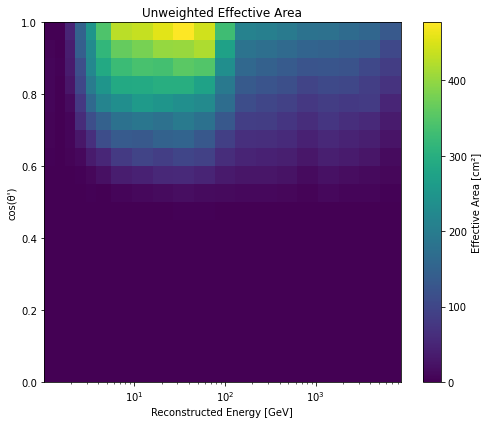

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(7, 6))

# Unweighted
c1 = ax.pcolormesh(
    E_bins_edge_HET, theta_bins_edge, effArea,
    shading='auto', cmap='viridis'#, vmin=vmin, vmax=vmax
    #, norm=LogNorm(vmin=vmin, vmax=vmax)
)
ax.set_xscale('log')
ax.set_xlabel("Reconstructed Energy [GeV]")
ax.set_ylabel("cos(θ')")
ax.set_title("Unweighted Effective Area")
fig.colorbar(c1, ax=ax, label='Effective Area [cm²]')

plt.tight_layout()
#fig.savefig(figPath + f"resolutionMap_HET_unweighted_exp{exponent:.1f}.png")
plt.show()

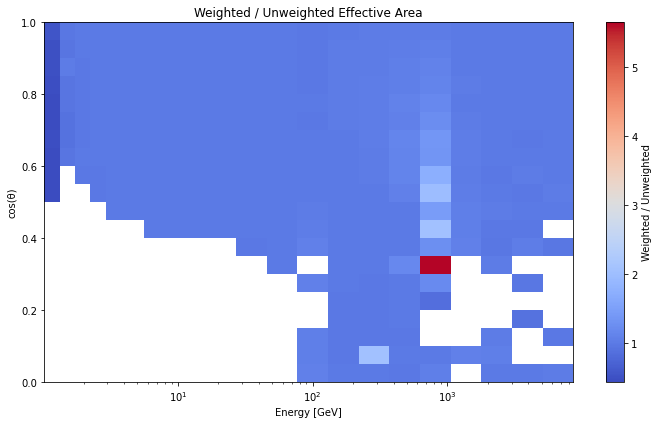

In [21]:
# Compute the ratio of weighted_ratio to unweighted_ratio
# Avoid division by zero
with np.errstate(divide='ignore', invalid='ignore'):
    ratio_map = np.divide(effArea_w, effArea)
    ratio_map[unweighted_ratio == 0] = np.nan

plt.figure(figsize=(10, 6))
pcm = plt.pcolormesh(
    E_bins_edge_HET, theta_bins_edge, ratio_map,
    shading='auto', cmap='coolwarm'
)
plt.xscale('log')
plt.xlabel("Energy [GeV]")
plt.ylabel("cos(θ)")
plt.title("Weighted / Unweighted Effective Area")
plt.colorbar(pcm, label='Weighted / Unweighted')
plt.tight_layout()
plt.show()

## Integrate over theta

In [22]:
# Sum over cos(theta) bins to get 1D energy-dependent effective areas
# Sum along axis=0 (cos(theta) axis) to integrate over theta
total_counts_1d = np.sum(total_counts, axis=0)
accepted_counts_1d = np.sum(accepted_counts, axis=0)
total_weights_1d = np.sum(total_weights, axis=0)
accepted_weights_1d = np.sum(accepted_weights, axis=0)

# Calculate effective areas as function of energy only
effArea_1d = np.divide(accepted_counts_1d * eff_area_geom, total_counts_1d,
                              out=np.zeros_like(accepted_counts_1d, dtype=float),
                              where=total_counts_1d!=0)

effArea_1d_w = np.divide(accepted_weights_1d * eff_area_geom, total_weights_1d,
                            out=np.zeros_like(accepted_weights_1d, dtype=float),
                            where=total_weights_1d!=0)



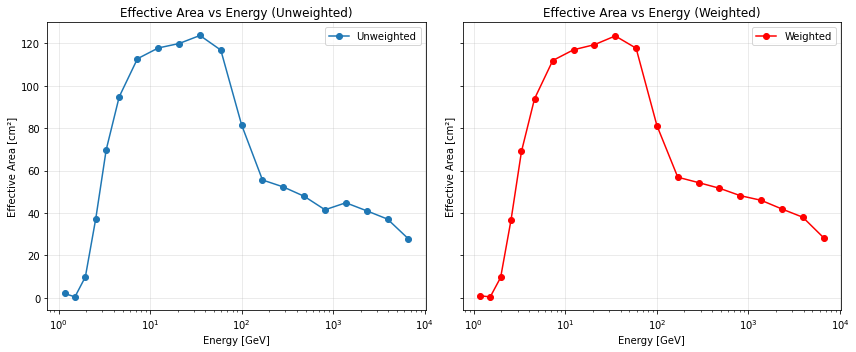

In [23]:


# Optional: Plot the 1D effective area
fig_1d, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Plot unweighted effective area
ax1.semilogx(E_bins_center_HET, effArea_1d, 'o-', label='Unweighted')
ax1.set_xlabel('Energy [GeV]')
ax1.set_ylabel('Effective Area [cm²]')
ax1.set_title('Effective Area vs Energy (Unweighted)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Plot weighted effective area
ax2.semilogx(E_bins_center_HET, effArea_1d_w, 'o-', color='red', label='Weighted')
ax2.set_xlabel('Energy [GeV]')
ax2.set_ylabel('Effective Area [cm²]')
ax2.set_title('Effective Area vs Energy (Weighted)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

## Explore angular evolution for each energy bin

In [24]:
## Plot angular evolution for a given energy bin
energy_bin_index = 10  # Change this to the desired energy bin index
if energy_bin_index < 0 or energy_bin_index >= n_E_bins_HET:
    raise ValueError(f"Energy bin index {energy_bin_index} is out of range. Must be between 0 and {n_E_bins_HET-1}.")   
# Extract the effective area for the specified energy bin
eff_area_for_energy_bin = df_results[df_results['E_bin_HET'] == energy_bin_index]['effArea']
eff_area_for_energy_bin_w = df_results[df_results['E_bin_HET'] == energy_bin_index]['effArea_w']    
# Extract the corresponding theta bins and their centers
theta_bins_for_energy = theta_bins_center
# Create the plot

plt.figure(figsize=(8, 5))
plt.plot(theta_bins_for_energy, eff_area_for_energy_bin.values, label='Unweighted', marker='o')
plt.plot(theta_bins_for_energy, eff_area_for_energy_bin_w.values, label='Weighted', marker='o')
plt.xscale('linear')
plt.xlabel("cos(θ)")
plt.ylabel("Effective Area [cm²]")
plt.title(f"Effective Area vs cos(θ) for Energy Bin {energy_bin_index} (HET)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig(figPath + f"effArea_vs_cosTheta_energyBin{energy_bin_index}_HET_exp{exponent:.1f}.png")
plt.show()

NameError: name 'df_results' is not defined

## Explore simple efficiency over all theta

In [ ]:
# Compute the unweighted inefficiency (total - accepted) for each energy bin, summed over all theta bins
efficiency_per_energy = (
    df_results.groupby('E_bin_HET')
    .apply(lambda x: (x['accepted'].sum() /x['total'].sum()))
)

grouped = df_results.groupby('E_bin_HET')


In [ ]:

# Plot inefficiency vs energy bin center
plt.figure(figsize=(8, 5))
plt.plot(E_bins_center_HET, efficiency_per_energy.values, marker='o', label='Unweighted efficiency')
plt.xscale('log')
plt.yscale('linear')
plt.xlabel("Energy [GeV]")
plt.ylabel("Efficiency (accepted/total)")
plt.title("Unweighted Efficiency vs Energy")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
efficiency_per_energy *= eff_area_geom


In [ ]:

# Plot inefficiency vs energy bin center
plt.figure(figsize=(8, 5))
plt.plot(E_bins_center_HET, efficiency_per_energy.values, marker='o', label='integral method')
plt.plot(df_results_energy['E_bin_HET'], df_results_energy['effArea'], label='Sum method', marker='o')
plt.xscale('log')
plt.yscale('linear')
plt.xlabel("Energy [GeV]")
plt.ylabel("Effective Area (accepted/total * cross section)")
plt.title("Unweighted Effective Area vs Energy")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Compute histogram counts for both datasets in energy bins
total_counts, _ = np.histogram(df['E_true'], bins=E_bins_edge_HET)
accepted_counts, _ = np.histogram(dfHET['E_true'], bins=E_bins_edge_HET)

# Compute bin centers for plotting
E_bin_centers = 0.5 * (E_bins_edge_HET[:-1] + E_bins_edge_HET[1:])

# Avoid division by zero in ratio calculation
efficiency = np.divide(
    accepted_counts, total_counts,
    out=np.zeros_like(accepted_counts, dtype=float),
    where=total_counts != 0
)

# Plot histograms and ratio
fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Top plot: total and accepted counts
axs[0].step(E_bin_centers, total_counts, where='mid', label='Total', color='blue')
axs[0].step(E_bin_centers, accepted_counts, where='mid', label='Accepted', color='red')
axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].set_ylabel("Counts")
axs[0].legend()
axs[0].set_title("Total vs Accepted Events per Energy Bin")

# Bottom plot: efficiency
axs[1].step(E_bin_centers, efficiency, where='mid', color='green')
axs[1].set_xscale('log')
axs[1].set_ylabel("Efficiency")
axs[1].set_xlabel("Energy [GeV]")
axs[1].set_title("Acceptance Efficiency per Energy Bin")

plt.tight_layout()
plt.show()